In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np
from datetime import datetime
import sentencepiece
import matplotlib.pyplot as plt

/Users/mohammadaminsedaghat/Desktop/attention/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [80]:
# Loading the train set:
ds = load_dataset("wmt/wmt14", "de-en",split="train",streaming=True)

for idx,row in enumerate(ds.iter(batch_size=8192)):
    df=pd.DataFrame(row["translation"])
    df["entext"] = df["en"].str.split().str.join(" ")
    df["detext"] = df["de"].str.split().str.join(" ")
    df = df.drop(columns=["de","en"])
    if idx == 0:
        df.to_csv("wmt14_train.csv",mode="w",index=False,header=True)
    else:
        df.to_csv("wmt14_train.csv",mode="a",index=False,header=False)
    print(f"{datetime.now()}: At index: {idx}")

2026-09-24 09:25:01.735060: At index: 0
2026-09-24 09:25:01.795568: At index: 1
2026-09-24 09:25:01.853556: At index: 2
2026-09-24 09:25:01.913816: At index: 3
2026-09-24 09:25:01.971482: At index: 4
2026-09-24 09:25:02.029482: At index: 5
2026-09-24 09:25:02.087476: At index: 6
2026-09-24 09:25:02.145305: At index: 7
2026-09-24 09:25:02.206310: At index: 8
2026-09-24 09:25:02.265110: At index: 9
2026-09-24 09:25:02.323626: At index: 10
2026-09-24 09:25:02.470415: At index: 11
2026-09-24 09:25:02.529612: At index: 12
2026-09-24 09:25:02.590618: At index: 13
2026-09-24 09:25:02.649939: At index: 14
2026-09-24 09:25:02.707668: At index: 15
2026-09-24 09:25:02.766263: At index: 16
2026-09-24 09:25:02.826243: At index: 17
2026-09-24 09:25:02.884295: At index: 18
2026-09-24 09:25:02.943723: At index: 19
2026-09-24 09:25:03.002682: At index: 20
2026-09-24 09:25:05.826648: At index: 21
2026-09-24 09:25:05.885074: At index: 22
2026-09-24 09:25:05.941686: At index: 23
2026-09-24 09:25:05.996466

In [82]:
# Loading the val set: 
ds = load_dataset("wmt/wmt14", "de-en",split="validation",streaming=True)
for idx,row in enumerate(ds.iter(batch_size=8192)):
    df=pd.DataFrame(row["translation"])
    df["entext"] = df["en"].str.split().str.join(" ")
    df["detext"] = df["de"].str.split().str.join(" ")
    df = df.drop(columns=["de","en"])
    if idx == 0:
        df.to_csv("wmt14_val.csv",mode="w",index=False,header=True)
    else:
        df.to_csv("wmt14_val.csv",mode="a",index=False,header=False)
    print(f"{datetime.now()}: At index: {idx}")

2026-09-24 09:27:12.905908: At index: 0


In [ ]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load("tokenizers/wmt14/bpe.model")
NUM_TOKENS=0
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)

In [ ]:
# Sorting val df for faster validation calculation (batches of same size get grouped together)
val_df = pd.read_csv("wmt14_val.csv")
val_df['en_enc'] = [len(encode(item)) for item in val_df["entext"]]
val_df['de_enc'] = [len(encode(item)) for item in val_df["detext"]]
val_df['ratio'] = val_df['en_enc'] / val_df['de_enc']
sorted_val_df = val_df.sort_values("en_enc")
print(NUM_TOKENS)
(sorted_val_df.drop(columns=["en_enc","de_enc","ratio"])).to_csv("wmt14_val.csv",index=False)

303892


In [71]:
df = pd.read_csv("wmt14_train.csv",nrows=1000)

In [ ]:
df['en_enc'] = [len(encode(item)) for item in df["entext"]]
df['de_enc'] = [len(encode(item)) for item in df["detext"]]
df['ratio'] = df['en_enc'] / df['de_enc']
sorted_df = df.sort_values("en_enc")
print(NUM_TOKENS)

92366


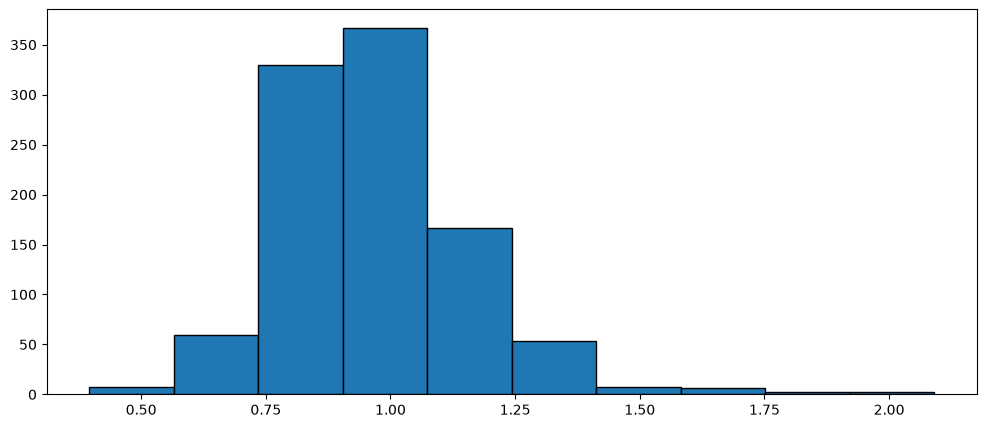

In [73]:
plt.figure(figsize=(12,5))
plt.hist(df["ratio"],edgecolor="black")
# plt.axline(xy1=(128,0),xy2=(128,25),color="green")
plt.show()

In [76]:
df[df["ratio"] == df["ratio"].max()].iloc[0,1]

'Das dritte Ziel besteht in einer städtischen und ländlichen Entwicklung im Rahmen einer ausgewogenen Raumordnungspolitik.'

In [77]:
df.iloc[571,1]

'Die Leitlinien gehen im übrigen von zwei horizontalen Prinzipien aus: Die Entwicklung des ländlichen Raums - und die Frage einer nachhaltigen Verkehrsstruktur, Frau Berichterstatterin, die mir seit langem am Herzen liegt, insbesondere seit meiner Zeit als Umweltminister meines Landes, gehört für mich in den Bereich der Entwicklung des ländlichen Raums - und das zweite Prinzip ist die Chancengleichheit, insbesondere zwischen Frauen und Männern, sowie die europäische Beschäftigungsstrategie und die Wirtschafts- und Währungsunion.'

In [62]:
from collections import deque

Data Filtering

In [ ]:
NUM_TOKENS=0
val_df = pd.read_csv("val_sorted_df.csv")
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True, add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# filter based on ratio. 
val_df['x_enc'] = [len(encode(item)) for item in val_df["entext"]]
# val_df["detext"] = val_df["detext"].str.replace("<br","")
# sorted_df = val_df.sort_values("x_enc").reset_index().drop(columns=["Unnamed: 0", "x_enc", "level_0"])
# sorted_df.to_csv("val_sorted_df.csv",index=False)
print(NUM_TOKENS)

In [ ]:
val_df.iloc[-1,4]

In [ ]:
NUM_TOKENS=0
train_df = pd.read_csv("train_filtered_df.csv").drop(columns=["Unnamed: 0"])
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True,add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
train_df['x_enc'] = [len(encode(item)) for item in train_df["entext"]]
train_df['y_enc'] = [len(encode(item)) for item in train_df["detext"]]
train_df["ratio"] = train_df["x_enc"] / train_df["y_enc"]
print(NUM_TOKENS)

In [ ]:
en_value_counts = train_df.groupby("entext")["entext"].transform("count")
de_value_counts = train_df.groupby("detext")["detext"].transform("count")
en_counter = train_df.groupby("entext").cumcount()
de_counter = train_df.groupby("detext").cumcount()
mask = (
    ((en_value_counts < 10) | (en_counter < 5)) & 
    ((de_value_counts < 10) | (de_counter < 5)) & 
    (train_df["x_enc"] >= 4) & 
    (train_df["y_enc"] > 4) & 
    (train_df["ratio"] >= 0.4) & 
    (train_df["ratio"] <= 2.5)
)
filtered_df = train_df[mask]

In [ ]:
filtered_df.head()

In [ ]:
filtered_df.drop(columns=["Unnamed: 0","x_enc","y_enc","ratio"]).to_csv("train_filtered_df.csv")

In [ ]:
mask.value_counts()

Curation

In [ ]:
df = pd.read_csv("data/wmt14/train_df.csv")

In [ ]:
NUM_TOKENS=0
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True,add_eos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids, dtype=np.int64)
# train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
df['x_enc'] = [len(encode(item)) for item in df["entext"]]
df['y_enc'] = [len(encode(item)) for item in df["detext"]]
df["ratio"] = df["x_enc"] / df["y_enc"]

In [ ]:
curated_df = df[df['ratio'] < 2].drop(columns=["x_enc","y_enc","ratio"])

hi?


In [ ]:
df.shape[0]-curated_df.shape[0]

98933

In [ ]:
curated_df.to_csv("data/wmt14_curated/train_df.csv")

Val Curation

In [ ]:
df = pd.read_csv("data/wmt14/val_df.csv")

In [ ]:
df['x_enc'] = [len(encode(item)) for item in df["entext"]]
df['y_enc'] = [len(encode(item)) for item in df["detext"]]
df["ratio"] = df["x_enc"] / df["y_enc"]

In [ ]:
sorted_df = df[df["ratio"] < 2]

In [ ]:
sorted_df = sorted_df.sort_values("x_enc").drop(columns=["x_enc","y_enc","ratio"])

In [ ]:
sorted_df.to_csv("data/wmt14_curated/val_df.csv")

In [ ]:
sorted_df.shape,df.shape

((2998, 2), (3000, 5))